# Лабораторна робота № 1

## Вхідний аналіз набору даних

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Пригадати роботу в Jupyter Notebook, бібліотеці `pandas` та побудову графіків —
і зробити це не на навчальному прикладі, а на реальному файлі, який ніхто не готував
спеціально для вас.

Ця робота виконується **до першої лекції**. Нічого нового знати не потрібно: усе,
що знадобиться, ви вже проходили в попередніх курсах. Усі поняття, яких ви тут
торкнетеся мимохідь, отримають назви й пояснення на лекціях 3 і 4.

### Дані

Файл `20171129_FINAL_FINAL.xlsx`, аркуш `Sheet1` — спостереження космічної погоди
за 28 серпня — 22 вересня 2017 року, зібрані з трьох різних джерел.

Файл видається **як є**, рівно в тому вигляді, у якому його колись вивантажили.
Ніхто не приводив його до ладу, і саме в цьому сенс: справжні дані здебільшого
надходять саме такими.

### Що ви маєте зробити

| Етап | Зміст | Де |
|---|---|---|
| 1 | Розібратися, що взагалі лежить у файлі | аудиторно |
| 2 | Виділити три таблиці й привести їх до робочого вигляду | аудиторно |
| 3 | Скласти паспорт даних: що є, чого бракує, що виглядає дивно | аудиторно |
| 4 | Об'єднати три таблиці в одну | аудиторно |
| 5 | Побудувати п'ять графіків, кожен — відповідь на питання | аудиторно + самостійно |
| 6 | Порівняти два графіки одних і тих самих даних | самостійно |
| 7 | Записати три спостереження про дані | самостійно |
| 8 | Декларація про використання інструментів ШІ | самостійно |

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Ноутбук має виконуватися згори
   донизу на чистому ядрі** (Kernel → Restart & Run All) без помилок — це перевіряється
   першою дією на захисті.
2. Файл `master_hourly.csv` — об'єднана таблиця з етапу 4.
3. Експорт ноутбука у HTML або PDF.
4. Заповнена декларація (етап 8). Без неї фінальна самоперевірка не проходить.

### Критерії оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Дані не опрацьовано, графіки не побудовано або побудовано з грубими помилками |
| 1 | Таблиці прочитано й кілька графіків побудовано, але типи графіків не відповідають даним, дивних значень не помічено |
| 2 | Таблиці розібрано й об'єднано, графіки коректні та підписані, але висновків під ними немає або вони формальні |
| 4 | Усе вище виконано, знайдено й пояснено дивні значення, під кожним графіком є змістовний висновок про дані |

**Головне про оцінку:** бали ставляться не за наявність графіка, а за речення під ним.
Код, який нічого не пояснює, коштує двох балів з чотирьох.

---
## Нагадування про Jupyter

Якщо давно не працювали — три речі, які знадобляться сьогодні:

* `Shift+Enter` виконує клітинку, `Esc` `A` / `Esc` `B` додає клітинку вище / нижче,
  `Esc` `M` перетворює клітинку на текстову (Markdown), `Esc` `Y` — назад на код.
* **Порядок виконання має значення.** Якщо ви правили клітинки в довільному порядку,
  результат може залежати від історії запусків. Перед здачею обов'язково
  **Kernel → Restart & Run All** — так ви побачите ноутбук очима викладача.
* Текстові клітинки — не прикраса. Висновки пишуться в них, а не в коментарях до коду.

---
## Крок 0. Ваші дані та варіант

Заповніть три змінні й виконайте обидві клітинки. Друга надрукує **ваше
індивідуальне завдання** — воно відрізняється від завдання сусіда.

In [35]:
ПІБ = 'Бойко Роман'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-32'      # напр. 'КН-31'
ВАРІАНТ = 4     # ваш номер за списком групи

assert ПІБ and ГРУПА and ВАРІАНТ, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ'

In [36]:
# --- клітинку не редагувати: вона видає ваше персональне завдання ------------
ПОТОКИ = ['P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']

ПАРИ = [('швидкість вітру', 'густина вітру'),
        ('швидкість вітру', 'потік P>10'),
        ('густина вітру', 'потік P>1'),
        ('радіопотік F10.7', 'потік P>10'),
        ('радіопотік F10.7', 'швидкість вітру'),
        ('потік E>0.8', 'потік P>10')]

АГРЕГАТИ = ['середнє', 'максимум', 'медіана', 'мінімум']

ПИТАННЯ = [
    'Скільки годин за все вікно ваш потік перевищував своє власне медіанне значення?',
    'У яку добу середнє значення вашого потоку було найбільшим? А найменшим?',
    'О котрій годині доби потік E>0.8 у середньому найбільший? Побудуйте графік середнього за годинами доби.',
    'Яка частка рядків об’єднаної таблиці має пропуск хоча б в одному стовпці?',
    'У який день радіопотік F10.7 був найбільшим і чи збігається цей день з піком вашого потоку?',
    'Порівняйте медіану вашого потоку за перший і за другий тиждень спостережень. У скільки разів вони відрізняються?',
    'Скільки годин поспіль тривала найдовша неперервна серія «активних» годин (група з етапу 4)?',
    'Який зі стовпців об’єднаної таблиці має найбільший розкид відносно власного середнього?',
    'Яку частку сумарного значення вашого потоку за все вікно дали 24 години навколо піку?',
    'Скільки різних діб потрапило у групу «активні» і скільки — у групу «дуже активні»?',
]

i = int(ВАРІАНТ)
завдання = {
    'ваш потік':                      ПОТОКИ[(i * 3 + 1) % 8],
    'ваша пара для графіка 3':        ' та '.join(ПАРИ[(i * 5 + 2) % 6]),
    'ваш агрегат для етапу 4':        АГРЕГАТИ[(i * 5 + 1) % 4],
    'ваше додаткове питання':         ПИТАННЯ[(i * 11 + 5) % 10],
}

print('ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · %s, %s, варіант %d' % (ПІБ, ГРУПА, i))
print('=' * 78)
for k, v in завдання.items():
    print('%-28s %s' % (k + ':', v))

ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · Бойко Роман, ШІ-32, варіант 4
ваш потік:                   P>100
ваша пара для графіка 3:     радіопотік F10.7 та швидкість вітру
ваш агрегат для етапу 4:     максимум
ваше додаткове питання:      Скільки різних діб потрапило у групу «активні» і скільки — у групу «дуже активні»?


Далі за текстом **«ваш потік»** означає стовпець, названий у першому рядку завдання.

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

ФАЙЛ = '20171129_FINAL_FINAL.xlsx'

---
# Етап 1. Що взагалі лежить у файлі

Перше правило роботи з незнайомими даними: спершу подивитися, потім рахувати.

### Завдання 1.1
Спробуйте прочитати аркуш `Sheet1` звичайним способом — `pd.read_excel(ФАЙЛ)` —
і виведіть перші рядки та типи стовпців.

*Очікуваний результат: результат буде дивним. Подивіться на назви стовпців і на
те, які там типи даних. Поясніть у наступній клітинці, чому так вийшло.*

In [4]:
pd.read_excel(ФАЙЛ)

,Unnamed: 0,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,http://umtof.umd.edu/pm/crn/,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
2,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
3,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
4,NaN,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7220,NaN,2017,9,21,2335,58017,84900,21.9,0.361,0.202,0.084,0.0717,0.0475,143000,32900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7221,NaN,2017,9,21,2340,58017,85200,14.1,0.343,0.309,0.118,0.0679,0.0328,143000,32100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7222,NaN,2017,9,21,2345,58017,85500,27.1,0.465,0.237,0.106,0.0593,0.0251,140000,32500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7223,NaN,2017,9,21,2350,58017,85800,23.7,0.36,0.205,0.127,0.091,0.0363,140000,32700,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
data = pd.read_excel(ФАЙЛ)
df = pd.DataFrame(data)
df.head()

,Unnamed: 0,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,http://umtof.umd.edu/pm/crn/,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
2,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
3,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
4,NaN,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN


In [6]:
df.dtypes

Unnamed: 0                                     float64
ftp://ftp.swpc.noaa.gov/pub/lists/particle/     object
Unnamed: 2                                      object
Unnamed: 3                                      object
Unnamed: 4                                      object
Unnamed: 5                                      object
Unnamed: 6                                      object
Unnamed: 7                                      object
Unnamed: 8                                      object
Unnamed: 9                                      object
Unnamed: 10                                     object
Unnamed: 11                                     object
Unnamed: 12                                     object
Unnamed: 13                                     object
Unnamed: 14                                     object
Unnamed: 15                                    float64
Unnamed: 16                                     object
Unnamed: 17                                     object
Unnamed: 1

**Відповідь 1.1:** *(чому звичайне читання дало саме такий результат)*

Звичайне читання через pd.read_excel() дало дивний результат, оскільки pandas за замовчуванням сприймає перший рядок аркуша як заголовки стовпців.
Функція випадково зчитала шматки тексту як назви колонок, присвоїла порожнім колонкам імена Unnamed: X, а решту тексту записала як значення рядків, заповнивши більшість інших клітинок пропусками NaN.

### Завдання 1.2
Прочитайте аркуш ще раз, але **без заголовка**: `pd.read_excel(ФАЙЛ, header=None)`.
Виведіть його розмір і подивіться на перші 30 рядків.

In [7]:

RAW = pd.read_excel(ФАЙЛ, header=None)
RAW.shape


(7226, 32)

In [8]:
df.head(30)

,Unnamed: 0,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,http://umtof.umd.edu/pm/crn/,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
2,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
3,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
4,NaN,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN
5,NaN,#,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,# Label: P > 1 = Particles at >1 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Measurement time (Year, Month, Day of Month, D...",NaN,NaN,NaN,NaN,NaN
7,NaN,# Label: P > 5 = Particles at >5 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,# Label: P >10 = Particles at >10 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,# Label: P >30 = Particles at >30 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Завдання 1.3
Для кожного стовпця порахуйте, скільки в ньому заповнених клітинок
(`RAW.notna().sum()`), і виведіть результат.

*Очікуваний результат: 32 числа. Серед них будуть нулі та згустки великих значень.
За цими згустками видно, що в аркуші **не одна таблиця, а кілька**, вставлені поруч.*

**Питання:** скільки таблиць в аркуші і які стовпці займає кожна?

In [9]:
RAW.notna().sum()



0        0
1     7223
2     7202
3     7202
4     7202
5     7203
6     7203
7     7198
8     7198
9     7198
10    7198
11    7198
12    7198
13    7198
14    7198
15       0
16      32
17      26
18      26
19      26
20       0
21       0
22       0
23       0
24     601
25     601
26     608
27     602
28     602
29     602
30     602
31     602
dtype: int64

**Відповідь 1.3:** *В аркуші знаходиться 3 окремі таблиці: 
Перша таблиця (A): займає стовпці з індексами 1–14. Містить 7200 заповнених рядків. 
Друга таблиця (B): займає стовпці з індексами 16–19. Містить 26 заповнених рядків. 
Третя таблиця (C): займає стовпці з індексами 24–31. Містить 600 заповнених рядків.*


### Завдання 1.4
Над кожною таблицею є кілька текстових рядків — це службовий опис від тих, хто дані
збирав. Виведіть їх і випишіть для кожної таблиці **джерело даних та одиниці
вимірювання**.

*Це найкорисніші п'ять хвилин роботи: жодної з цих відомостей у самій таблиці немає,
і без них ви не знатимете, у чому вимірюєте.*

In [10]:
print("Table A info")
print('\n'.join(RAW[1].dropna().head(21).astype(str)))
print("\n\nTable B info")
print('\n'.join(RAW[16].dropna().head(7).astype(str)))
print("\n\nTable C info")
print('\n'.join(RAW[26].dropna().head(6).astype(str)))


Table A info
ftp://ftp.swpc.noaa.gov/pub/lists/particle/
:Data_list: 20170901_Gs_part_5m.txt
:Created: 2017 Sep 02 0011 UTC
# Prepared by the U.S. Dept. of Commerce, NOAA, Space Weather Prediction Center
# Please send comments and suggestions to SWPC.Webmaster@noaa.gov 
# 
# Label: P > 1 = Particles at >1 Mev
# Label: P > 5 = Particles at >5 Mev
# Label: P >10 = Particles at >10 Mev
# Label: P >30 = Particles at >30 Mev
# Label: P >50 = Particles at >50 Mev
# Label: P>100 = Particles at >100 Mev
# Label: E>0.8 = Electrons at >0.8 Mev
# Label: E>2.0 = Electrons at >2.0 Mev
# Label: E>4.0 = Electrons at >4.0 Mev
# Units: Particles = Protons/cm2-s-sr
# Units: Electrons = Electrons/cm2-s-sr
# Source: GOES-15
# Location: W135
# Missing data: -1.00e+05
5-minute  GOES-15 Solar Particle and Electron Flux


Table B info
ftp://ftp.swpc.noaa.gov/pub/indices/old_indices/2017Q3_DSD.txt
Product: Daily Solar Data         quar_DSD.txt
:Issued: 0825 UT 04 Oct 2017
#
#  Prepared by the U.S. Dept. of Com

**Відповідь 1.4:**

| Таблиця | Джерело | Одиниці вимірювання |
|---|---|---|
| A | GOES-15 | Units: Particles = Protons/cm2-s-sr
Units: Electrons = Electrons/cm2-s-sr |
| B | NOAA | No data |
| C | SOHO CELIAS Proton Monitor | Proton speed [km/sec]
Proton density [protons per cubic centimeter] |


---
# Етап 2. Три таблиці в робочому вигляді

У файлі три таблиці. Ось що в них лежить — решту ви вже знайшли самі:

| Таблиця | Стовпці аркуша | Що це | Один рядок = |
|---|---|---|---|
| A | B–O | вимірювання із супутника GOES-15: потоки частинок різної енергії | 5 хвилин |
| B | Q–T | добовий показник сонячної активності F10.7 | доба |
| C | Y–AF | швидкість і густина сонячного вітру | година |

### Завдання 2.1
Виділіть кожну таблицю в окремий `DataFrame` — назвіть їх `A`, `B` і `C`.
Дайте стовпцям осмислені назви й перетворіть значення на числа
(`pd.to_numeric(..., errors='coerce')` стане в пригоді).

In [11]:
A = RAW.iloc[26:, 1:15].copy()
A.columns = ['YR', 'MO', 'DA', 'HHMM', 'Julian_Day', 'Day_of_the', 'P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']
A = A.apply(pd.to_numeric, errors='coerce').dropna(how='all')

B = RAW.iloc[27:, 16:20].copy()
B.columns = ['YR', 'MO', 'DA', 'RADIO FLUX 10.7']
B = B.apply(pd.to_numeric, errors='coerce').dropna(how='all')

C = RAW.iloc[27:, 26:32].copy()
C.columns = ['YR', 'MO', 'DA', 'HH', 'SPEED', 'DENSITY']
C = C.apply(pd.to_numeric, errors='coerce').dropna(how='all')

### Завдання 2.2
У кожній таблиці дата й час записані **по-різному** й розкидані по кількох стовпцях.
Зберіть для кожної таблиці один стовпець `ts` типу `datetime`.

Після цього обов'язково виведіть для кожної таблиці найранішу й найпізнішу дату.

*Очікуваний результат: усі три таблиці мають лежати в межах серпня–вересня 2017 року.
Якщо у вас вийшов інший рік — придивіться, як записано рік у тій таблиці, і виправте.*

In [12]:
# ВАШ КОД
hhmm = A['HHMM'].astype(int).astype(str).str.zfill(4)
A['ts'] = pd.to_datetime(A['YR'].astype(int).astype(str) + "-" +
                         A['MO'].astype(int).astype(str) + "-" +
                         A['DA'].astype(int).astype(str) + " " +
                         hhmm.str.slice(0, 2) + ':' + hhmm.str.slice(2, 4))

B['ts'] = pd.to_datetime(B['YR'].astype(int).astype(str) + "-" +
                         B['MO'].astype(int).astype(str) + "-" +
                         B['DA'].astype(int).astype(str))

yr = (C['YR'].astype(int) + 2000).astype(str)
C['ts'] = pd.to_datetime(yr + "-" +
                         C['MO'].astype(int).astype(str) + "-" +
                         C['DA'].astype(int).astype(str) + " " +
                         C['HH'].astype(int).astype(str) + ":00")

**Самоперевірка етапу 2.** Клітинка має виконатися без помилок.

In [13]:
assert len(A) == 7200, 'у таблиці A має бути 7200 рядків, а є %d' % len(A)
assert len(B) == 25,   'у таблиці B має бути 25 рядків, а є %d' % len(B)
assert len(C) == 601,  'у таблиці C має бути 601 рядок, а є %d' % len(C)
for назва, т in [('A', A), ('B', B), ('C', C)]:
    рік = pd.to_datetime(т['ts']).dt.year
    assert рік.min() == 2017 and рік.max() == 2017, 'у таблиці %s рік не 2017 — перевірте збирання дати' % назва
print('Етап 2 пройдено')

Етап 2 пройдено


---
# Етап 3. Паспорт даних

### Завдання 3.1
Для кожної таблиці виведіть: розмір, типи стовпців, кількість пропусків у кожному
стовпці, кількість повних дублікатів рядків і описові статистики (`describe()`).

In [14]:
for name, df_data in [('A', A), ('B', B), ('C', C)]:
    print(f"\n=== Table {name} ===")

    print(f"Size: {df_data.shape}")
    print(f"Data types:\n {df_data.dtypes}")
    print(f"\nDuplicates: {df_data.duplicated().sum()}") 
    print(f"Spaces:\n {df_data.isna().sum()}")
    print("\nOther data:") 
    print(df_data.describe())


=== Table A ===
Size: (7200, 15)
Data types:
 YR                     int64
MO                     int64
DA                     int64
HHMM                   int64
Julian_Day             int64
Day_of_the             int64
P>1                  float64
P>5                  float64
P>10                 float64
P>30                 float64
P>50                 float64
P>100                float64
E>0.8                float64
E>2.0                float64
ts            datetime64[us]
dtype: object

Duplicates: 0
Spaces:
 YR            0
MO            0
DA            0
HHMM          0
Julian_Day    0
Day_of_the    0
P>1           3
P>5           3
P>10          3
P>30          3
P>50          3
P>100         3
E>0.8         3
E>2.0         3
ts            0
dtype: int64

Other data:
           YR           MO           DA         HHMM    Julian_Day    Day_of_the           P>1          P>5         P>10         P>30         P>50       P>100          E>0.8          E>2.0  \
count  7200.0  7200.00

### Завдання 3.2 — дивні значення
Подивіться на рядок `min` у таблиці `describe()` для таблиці C.

Швидкість і густина — фізичні величини, які **не можуть бути від'ємними**.
Знайдіть від'ємні значення, порахуйте, скільки їх, і поверніться до службового опису
з завдання 1.4: там написано, що вони означають.

Замініть ці значення на `NaN` і покажіть, як після цього змінилися середнє й мінімум.

*Очікуваний результат: два числа «до» і «після» для кожного зі стовпців.*

In [15]:
# ВАШ КОД
import numpy as np
neg_speed_count = (C['SPEED']<0).sum()
neg_density_count = (C['DENSITY']<0).sum()
print(f"Negative speed count: {neg_speed_count}")
print(f"Negative density count: {neg_density_count}")




Negative speed count: 8
Negative density count: 8


In [16]:
speed_min_before = C['SPEED'].min()
speed_mean_before = C['SPEED'].mean()
density_min_before = C['DENSITY'].min()
density_mean_before = C['DENSITY'].mean()
C.loc[C['SPEED']<0, 'SPEED'] = np.nan
C.loc[C['DENSITY']<0, 'DENSITY'] = np.nan
speed_min_after = C['SPEED'].min()
speed_mean_after = C['SPEED'].mean()
density_min_after = C['DENSITY'].min()
density_mean_after = C['DENSITY'].mean()
print(f"SPEED min: {speed_min_before} -> {speed_min_after}")
print(f"SPEED mean: {speed_mean_before:.2f} -> {speed_mean_after:.2f}")
print(f"DENSITY min: {density_min_before} -> {density_min_after}")
print(f"DENSITY mean: {density_mean_before:.2f} -> {density_mean_after:.2f}")

SPEED min: -1.0 -> 277.0
SPEED mean: 506.55 -> 513.39
DENSITY min: -1.0 -> 0.1
DENSITY mean: 2.91 -> 2.96


**Відповідь 3.2:** *(що це за значення, скільки їх, як вони спотворювали середнє)*

У стовпцях SPEED та DENSITY знайдено по 8 від'ємних значень -1.0. 
Від'ємні значення використовуються як маркування пропущених даних. Через наявність цих значень оригінальне середнє значення було занижене, тому їх заміна на NaN робить статистику коректною.

### Завдання 3.3 — питання на подумати
У таблиці A є стовпці, для яких `describe()` слухняно рахує середнє й стандартне
відхилення, хоча ці числа не мають жодного сенсу.

Знайдіть їх і поясніть своїми словами, чому середнє для них безглузде.

*Підказка: не кожне число в таблиці є результатом вимірювання.*

> Це питання не має однієї «правильної» відповіді з підручника — на нього ви
> відповідаєте з власного здорового глузду. Формальне пояснення буде на лекції 3.

In [17]:
# ВАШ КОД


**Відповідь 3.3:** *(які це стовпці та чому середнє для них не має сенсу)*

Середнє значення не має жодного сенсу для стовпців, які позначають час та дату: YR, MO, DA, HHMM, Julian_Day та Day_of_the.
Ці колонки є мітками часу, а не результатами вимірювань.

---
# Етап 4. Об'єднання трьох таблиць в одну

Таблиці мають різний крок у часі: 5 хвилин, година і доба. Щоб працювати з ними
разом, потрібна спільна сітка. Беремо **годину**.

Кожна таблиця потребує своєї дії:

1. **A: 5 хвилин → година.** Кілька рядків згортаються в один — це `resample` + агрегація.
2. **C: уже година.** Просте з'єднання по спільному стовпцю `ts` — `merge`.
3. **B: доба → година.** Навпаки, одне значення розтягується на 24 години доби.

### Завдання 4.1
Зведіть таблицю A до погодинної сітки. Для кожного потоку порахуйте **два** числа
за годину: середнє і максимум.

In [18]:
main_indexes_A = ['P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']
A_sub = A[['ts'] + main_indexes_A].copy()
A_sub = A_sub.set_index('ts')
A_hourly = A_sub.resample('1h').agg(['mean','max'])
A_hourly.columns = [f"{col}_{func}" for col, func in A_hourly.columns]

A_hourly = A_hourly.reset_index()
display(A_hourly.head())
    

,ts,P>1_mean,P>1_max,P>5_mean,P>5_max,P>10_mean,P>10_max,P>30_mean,P>30_max,P>50_mean,P>50_max,P>100_mean,P>100_max,E>0.8_mean,E>0.8_max,E>2.0_mean,E>2.0_max
0,2017-08-28 00:00:00,9.778333,19.40,0.324917,0.690,0.192917,0.314,0.098850,0.2240,0.077583,0.1780,0.040692,0.0793,20941.666667,23600.0,1011.583333,1180.0
1,2017-08-28 01:00:00,7.994167,13.60,0.291667,0.512,0.156583,0.259,0.072583,0.0919,0.058700,0.0798,0.029950,0.0471,18091.666667,20600.0,713.000000,907.0
2,2017-08-28 02:00:00,6.099167,10.80,0.283000,0.479,0.177667,0.321,0.084450,0.1210,0.069642,0.1110,0.035025,0.0595,14108.333333,15000.0,380.833333,475.0
3,2017-08-28 03:00:00,4.752500,7.76,0.236833,0.329,0.166333,0.244,0.087658,0.1800,0.068092,0.1390,0.035517,0.0818,12766.666667,13100.0,267.916667,284.0
4,2017-08-28 04:00:00,4.158333,6.62,0.334917,0.539,0.208333,0.309,0.084800,0.1530,0.072850,0.1420,0.039708,0.0694,11333.333333,12300.0,203.000000,234.0


### Завдання 4.2
У вашому завданні названо агрегат (`середнє`, `максимум`, `медіана` або `мінімум`).

Візьміть ваш потік за одну добу, порахуйте для нього по годинах ваш агрегат і ще один
на ваш вибір, і побудуйте обидві криві на одному графіку.

**Питання:** чим вони відрізняються і в якій ситуації різниця між ними стане суттєвою?

Text(0, 0.5, 'P>100 value')

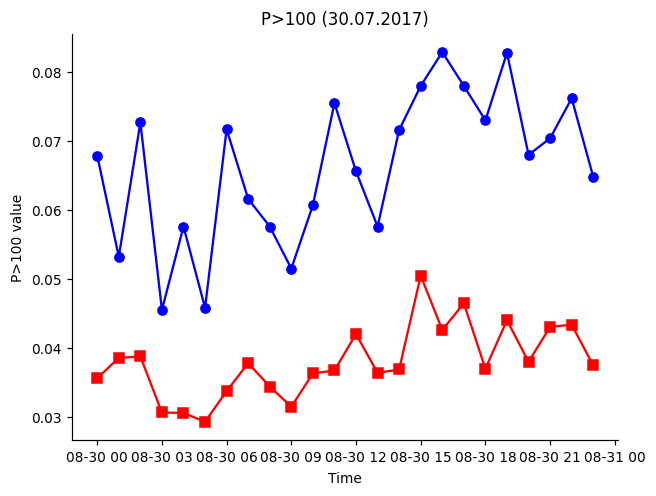

In [19]:
# ВАШ КОД
one_day_data = A[(A['ts']>='2017-08-30') & (A['ts']<'2017-08-31')].copy()
one_day_data = one_day_data.set_index('ts')
hourly_stats = one_day_data['P>100'].resample('1h').agg(['mean', 'max'])
plt.plot(hourly_stats.index, hourly_stats['max'], label="Maximum", marker = "o", color="blue")
plt.plot(hourly_stats.index, hourly_stats['mean'], label="Mean", marker = "s", color="red")
plt.title('P>100 (30.07.2017)')
plt.xlabel('Time')
plt.ylabel('P>100 value')

**Відповідь 4.2:** *(чим відрізняються криві та коли це важливо)*

Максимум показує максимальне значення P>100 протягом години, тоді як середнє значення розподіляє їх на всю годину.
Різниця між ними стає найбільшою під час різких сонячних аномалій.

### Завдання 4.3
Об'єднайте три таблиці в одну — назвіть її `M`. Виведіть її розмір і всі рядки,
у яких є хоча б один пропуск.

**Зверніть увагу:** таблиці закінчуються не в один і той самий момент. Тому результат
залежить від того, який тип об'єднання ви оберете (`how='inner'` чи `how='outer'`).
Спробуйте обидва, подивіться, чим відрізняється кількість рядків, і поясніть свій вибір.

In [20]:
# ВАШ КОД
A_hourly['date'] = A_hourly['ts'].dt.date
B['date']=B['ts'].dt.date
B_clean = B[['date', 'RADIO FLUX 10.7']]
C_clean = C[['ts', 'SPEED', 'DENSITY']]

M = pd.merge(A_hourly, C_clean, on='ts', how='inner')
M = pd.merge(M, B_clean, on='date', how='inner')
M = M.drop(columns=['date'])
M.shape
M

,ts,P>1_mean,P>1_max,P>5_mean,P>5_max,P>10_mean,P>10_max,P>30_mean,P>30_max,P>50_mean,P>50_max,P>100_mean,P>100_max,E>0.8_mean,E>0.8_max,E>2.0_mean,E>2.0_max,SPEED,DENSITY,RADIO FLUX 10.7
0,2017-08-28 00:00:00,9.778333,19.40,0.324917,0.690,0.192917,0.314,0.098850,0.2240,0.077583,0.1780,0.040692,0.0793,20941.666667,23600.0,1011.583333,1180.0,285.0,3.0,82.0
1,2017-08-28 01:00:00,7.994167,13.60,0.291667,0.512,0.156583,0.259,0.072583,0.0919,0.058700,0.0798,0.029950,0.0471,18091.666667,20600.0,713.000000,907.0,305.0,3.4,82.0
2,2017-08-28 02:00:00,6.099167,10.80,0.283000,0.479,0.177667,0.321,0.084450,0.1210,0.069642,0.1110,0.035025,0.0595,14108.333333,15000.0,380.833333,475.0,309.0,1.7,82.0
3,2017-08-28 03:00:00,4.752500,7.76,0.236833,0.329,0.166333,0.244,0.087658,0.1800,0.068092,0.1390,0.035517,0.0818,12766.666667,13100.0,267.916667,284.0,304.0,2.0,82.0
4,2017-08-28 04:00:00,4.158333,6.62,0.334917,0.539,0.208333,0.309,0.084800,0.1530,0.072850,0.1420,0.039708,0.0694,11333.333333,12300.0,203.000000,234.0,302.0,2.3,82.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,2017-09-21 19:00:00,63.166667,93.10,0.372500,0.795,0.229833,0.472,0.110642,0.1570,0.074300,0.1050,0.040192,0.0687,180250.000000,186000.0,65750.000000,66800.0,394.0,1.3,73.0
596,2017-09-21 20:00:00,42.102500,78.90,0.397500,0.833,0.226833,0.429,0.089325,0.1380,0.069983,0.1050,0.039692,0.0737,178750.000000,186000.0,63175.000000,70500.0,379.0,1.8,73.0
597,2017-09-21 21:00:00,50.783333,71.70,0.489250,0.788,0.317583,0.501,0.121358,0.2040,0.077467,0.1470,0.033417,0.0524,175833.333333,177000.0,58350.000000,60300.0,380.0,1.8,73.0
598,2017-09-21 22:00:00,39.000000,48.80,0.350000,0.536,0.200250,0.310,0.094358,0.1430,0.070633,0.1080,0.039600,0.0798,167750.000000,176000.0,49366.666667,54400.0,387.0,1.1,73.0


**Відповідь 4.3:** *(який тип об'єднання обрано, скільки рядків дає кожен і чому)*

Якщо використовувати how='outer', розмір таблиці виходить 601 рядок, оскільки таблиця C має один запис - 2017-09-22 00:00:00, якого немає в таблиці A.
Було обрано тип об'єднання how='inner', який дає рівно 600 рядків. Він залишає тільки ті години, для яких є дані в усіх таблицях.

### Завдання 4.4 — поділ на групи
Щоб далі було що з чим порівнювати, поділіть години на три групи за значенням
**максимуму потоку P>10 за годину**:

| Група | Умова |
|---|---|
| `тиха` | менше 10 |
| `активна` | від 10 до 1000 |
| `дуже активна` | 1000 і більше |

Додайте до `M` стовпець `група` і виведіть, скільки годин потрапило в кожну.

> Це не вигадані числа: саме такі пороги використовує метеослужба космічної погоди
> NOAA. Чому вони саме такі — питання не сьогоднішньої роботи.

In [21]:
# ВАШ КОД
cond = [
    M['P>10_max']<10,
    (M['P>10_max']>=10) & (M['P>10_max']< 1000),
    M['P>10_max']>=1000
] 
groups=['тиха', 'активна', 'дуже активна']
M['група'] = np.select(cond, groups, default='undefined')
M['група'].value_counts()

група
тиха            411
активна         171
дуже активна     18
Name: count, dtype: int64

**Самоперевірка етапу 4.**

In [22]:
assert M is not None, 'таблиця M не побудована'
assert 'ts' in M.columns, 'у таблиці M потрібен стовпець ts'
assert 'група' in M.columns, 'у таблиці M потрібен стовпець «група»'
assert 590 <= len(M) <= 605, 'очікується близько 600 рядків, а є %d — перевірте об’єднання' % len(M)
print('Етап 4 пройдено:', len(M), 'рядків')

Етап 4 пройдено: 600 рядків


---
# Етап 5. П'ять графіків — п'ять питань

Графік будується як **відповідь на питання**, а не «щоб був».

**Вимоги до кожного графіка:**

* підписані обидві осі, з одиницями вимірювання;
* заголовок;
* під графіком, у текстовій клітинці, — **одне речення про дані**.
  Не «на графіку зображено потік протонів», а твердження на кшталт
  «більшість годин потік не перевищує 60, але кілька годин дають значення у сотні разів більші».

> Не кожне питання має відповідь «так, зв'язок є». Якщо на графіку нічого не видно —
> так і напишіть. Відсутність зв'язку — це теж результат, і чесно про неї написати
> важливіше, ніж підбирати ракурс, у якому «щось наче проглядається».

### Графік 1. Як розподілені значення вашого потоку?
Побудуйте гістограму вашого потоку (середнє за годину). Порахуйте окремо середнє
й медіану цього стовпця.

Якщо гістограма вийде нечитабельною — стовпчик біля нуля і порожньо далі — не
залишайте так. Спробуйте побудувати гістограму від логарифма значень
(`np.log10`) і подивіться, що зміниться.

**Питання:** чому середнє й медіана так сильно відрізняються?

Mean: 1.6586235517676766
Median: 0.0394875


Text(0, 0.5, 'Hours')

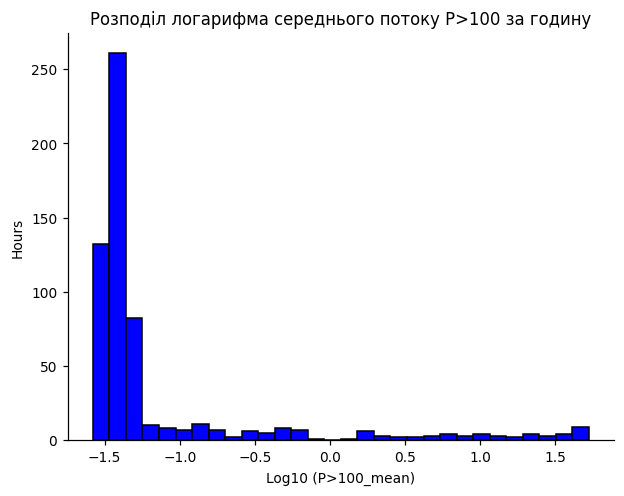

In [23]:
# ВАШ КОД
mean_val = M['P>100_mean'].mean()
median_val = M['P>100_mean'].median()
print(f"Mean: {mean_val}")
print(f"Median: {median_val}")
data_for_hist = M.loc[M['P>100_mean']>0, 'P>100_mean'].dropna()
plt.hist(np.log10(data_for_hist), bins=30, color='blue', edgecolor='black')

plt.title('Розподіл логарифма середнього потоку P>100 за годину')
plt.xlabel('Log10 (P>100_mean)')
plt.ylabel('Hours')

**Висновок:**

Середнє і медіана відрізняються в рази: переважну більшість годин потік залишається на дуже низькому рівні, але під час рідкісних сонячних спалахів виникають екстремально великі значення,
які перетягують на себе середнє арифметичне, майже не впливаючи на медіану.

### Графік 2. Чи відрізняється швидкість вітру між групами годин?
Побудуйте діаграму розмаху (`boxplot`) швидкості сонячного вітру окремо для кожної
групи з завдання 4.4.

Text(0, 0.5, 'Швидкість вітру (км/с)')

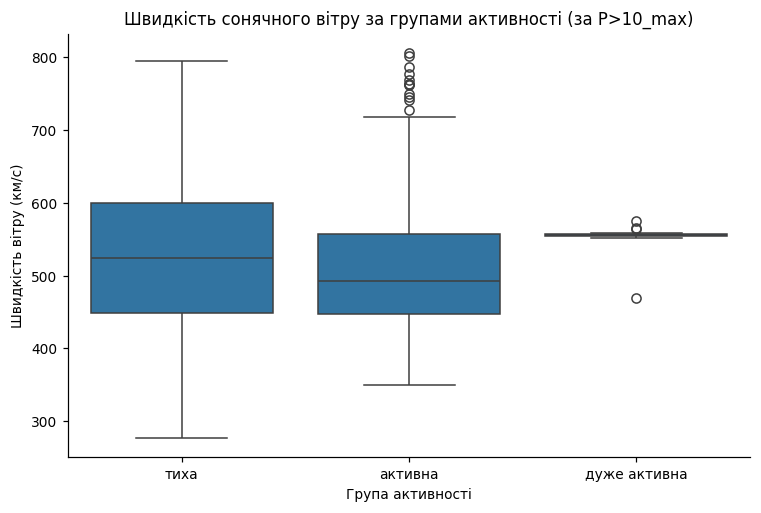

In [24]:

import seaborn as sns
plt.figure(figsize=(8, 5))
sns.boxplot(data=M, x='група', y='SPEED', order=['тиха', 'активна', 'дуже активна'])
plt.title('Швидкість сонячного вітру за групами активності (за P>10_max)')
plt.xlabel('Група активності')
plt.ylabel('Швидкість вітру (км/с)')

**Висновок:**

Діаграма розмаху показує, що у години, які класифіковані як "дуже активні", швидкість сонячного вітру в середньому значно вища та має більший розкид порівняно з "тихими" годинами, де швидкість стабільніша і нижча.

### Графік 3. Чи пов'язані змінні вашої пари?
Побудуйте діаграму розсіювання для пари з вашого завдання. Порахуйте коефіцієнт
кореляції між ними.

Correlation: 0.05929942026774891


Text(0, 0.5, 'WIND SPEED (km/sec)')

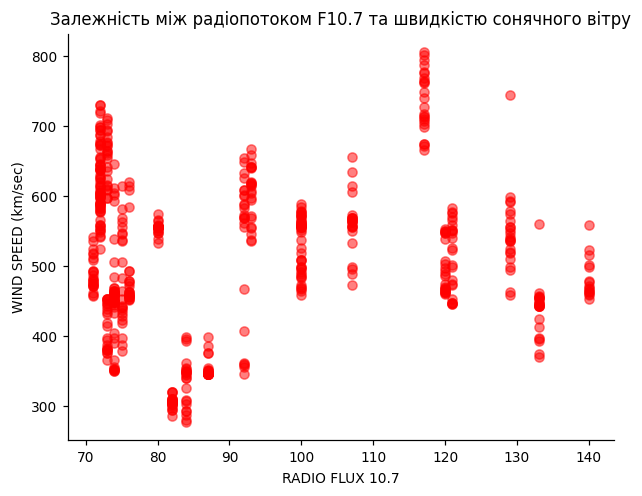

In [25]:
# ВАШ КОД
correlation = M['RADIO FLUX 10.7'].corr(M['SPEED'])
print(f'Correlation: {correlation}')

plt.scatter(M['RADIO FLUX 10.7'], M['SPEED'],alpha=0.5, color = 'red')

plt.title('Залежність між радіопотоком F10.7 та швидкістю сонячного вітру')
plt.xlabel('RADIO FLUX 10.7')
plt.ylabel('WIND SPEED (km/sec)')


**Висновок:**

Точки на діаграмі утворюють вертикальні смуги через те, що показник F10.7 має добовий крок і не змінюється щогодини, а низький коефіцієнт кореляції свідчить про те,
що прямого лінійного зв'язку між добовим радіопотоком та погодинною швидкістю вітру в цьому періоді немає.

### Графік 4. Скільки годин у кожній групі?
Побудуйте стовпчикову діаграму кількості годин за групами. Підпишіть кожен стовпчик
кількістю годин і відсотком від загальної кількості.

<function matplotlib.pyplot.show(close=None, block=None)>

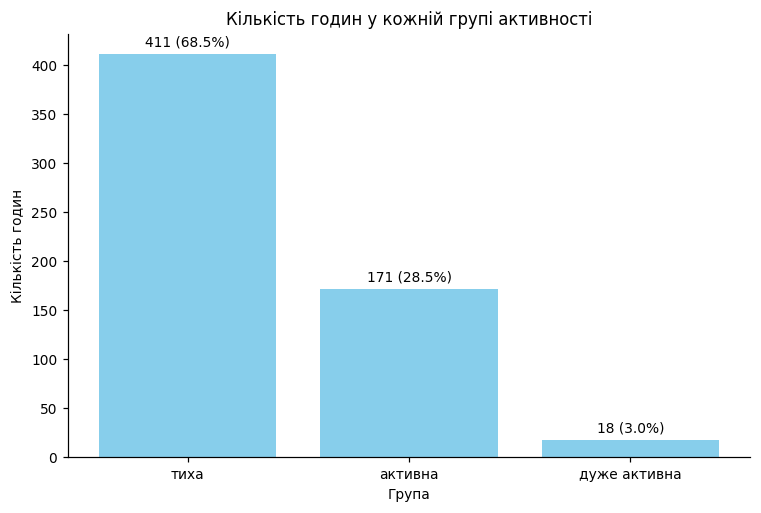

In [26]:
# ВАШ КОД
groups_counter = M['група'].value_counts()
total_hours = len(M)

plt.figure(figsize=(8, 5))
bar_diagram = plt.bar(groups_counter.index, groups_counter.values, color="skyblue")

plt.title('Кількість годин у кожній групі активності')
plt.xlabel('Група')
plt.ylabel('Кількість годин')

for bar in bar_diagram:
    yval = bar.get_height()
    percent = (yval / total_hours) * 100
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, f'{yval} ({percent:.1f}%)', ha='center', va='bottom')

plt.show

**Висновок:**

Переважна більшість часу погода перебуває у "тихій" фазі, тоді як періоди активності "дуже активна" - є надзвичайно рідкісними подіями.

### Графік 5. Як усе це виглядало в часі?
Побудуйте лінійний графік максимуму потоку P>10 за годину за весь період спостережень.

Якщо крива виявиться нечитабельною — згадайте, що допомогло в графіку 1.

(array([17407., 17410., 17414., 17418., 17422., 17426., 17430.]),
 [Text(17407.0, 0, '2017-08-29'),
  Text(17410.0, 0, '2017-09-01'),
  Text(17414.0, 0, '2017-09-05'),
  Text(17418.0, 0, '2017-09-09'),
  Text(17422.0, 0, '2017-09-13'),
  Text(17426.0, 0, '2017-09-17'),
  Text(17430.0, 0, '2017-09-21')])

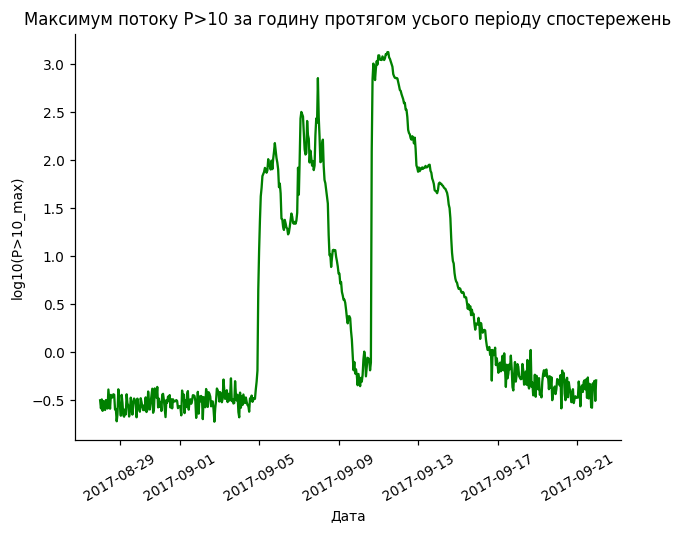

In [27]:
# ВАШ КОД
plt.plot(M['ts'], np.log10(M['P>10_max']), color="green")
plt.title('Максимум потоку P>10 за годину протягом усього періоду спостережень')
plt.xlabel('Дата')
plt.ylabel('log10(P>10_max)')
plt.xticks(rotation=30)

**Висновок:**

На графіку чітко видно кілька `екстремальних спалахів на початку вересня, які у тисячі разів перевищують звичний рівень потоку протонів у решту днів.

---
# Етап 6. Два графіки одних і тих самих даних

Нижче побудовано два графіки. Дані в них **одні й ті самі** — це той самий стовпець
з тієї самої таблиці, жодне число не змінено.

Виконайте клітинку й подивіться на обидва.

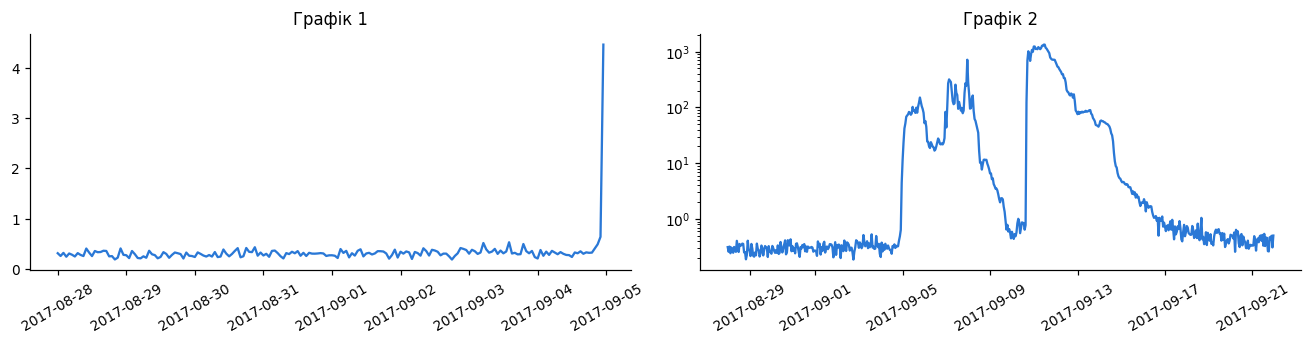

In [28]:
СТОВПЕЦЬ = 'P>10_max'   # <- впишіть назву свого стовпця з МАКСИМУМОМ P>10 за годину

вікно = M[(M['ts'] >= '2017-08-28') & (M['ts'] < '2017-09-05')]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))

ax[0].plot(вікно['ts'], вікно[СТОВПЕЦЬ], color='#2a78d6')
ax[0].set_title('Графік 1')
ax[0].tick_params(axis='x', rotation=30)

ax[1].plot(M['ts'], M[СТОВПЕЦЬ], color='#2a78d6')
ax[1].set_yscale('log')
ax[1].set_title('Графік 2')
ax[1].tick_params(axis='x', rotation=30)

fig.tight_layout()
plt.show()

### Завдання 6.1
Дайте відповідь на три питання:

1. Який висновок про космічну погоду у вересні 2017 року зробить людина, яка бачила
   **тільки перший** графік?
2. Який висновок зробить людина, яка бачила **тільки другий**?
3. Чим ці два графіки відрізняються між собою? Назвіть **дві** відмінності —
   вони обидві є в коді вище.

*Жодне число в обох графіках не підроблене. Різниця виникла тільки через те,
як їх побудували.*

**Відповідь 6.1:**

1. Висновок з першого графіка:
2. Висновок з другого графіка:
3. Дві відмінності між ними:


1. Висновок з першого графіка: Людина подумає, що космічна погода була відносно спокійною, з невеликими коливаннями в межах кількох одиниць, і жодних екстремальних подій не відбувалося.
2. Висновок з другого графіка: Людина подумає, що космічна погода постійно і сильно штормить протягом усього місяця, і що коливання майже такі самі, як і пікові значення.
3. Дві відмінності між ними: 
Різний часовий діапазон: перший графік показує лише перший тиждень, до початку сильних спалахів, а другий показує весь місяць.
Різна шкала осі Y: перший графік використовує звичайну шкалу, а другий — логарифмічну, яка візуально стискає величезні спалахи і розтягує дрібний шум.

### Завдання 6.2
Уявіть, що вам потрібно **одним графіком** чесно показати, що відбувалося в цьому
періоді. Побудуйте його самі й підпишіть заголовком, який формулює висновок.

Поясніть у клітинці нижче, чому ви обрали саме такий вигляд.

(array([17407., 17410., 17414., 17418., 17422., 17426., 17430.]),
 [Text(17407.0, 0, '2017-08-29'),
  Text(17410.0, 0, '2017-09-01'),
  Text(17414.0, 0, '2017-09-05'),
  Text(17418.0, 0, '2017-09-09'),
  Text(17422.0, 0, '2017-09-13'),
  Text(17426.0, 0, '2017-09-17'),
  Text(17430.0, 0, '2017-09-21')])

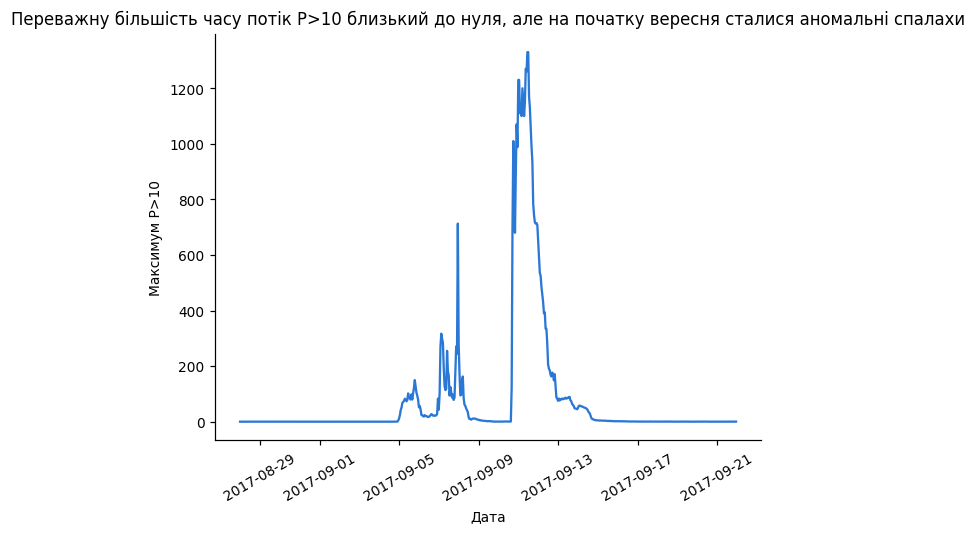

In [29]:
# ВАШ КОД
plt.plot(M['ts'], M['P>10_max'], color='#2a78d6')

plt.title('Переважну більшість часу потік P>10 близький до нуля, але на початку вересня сталися аномальні спалахи')
plt.xlabel('Дата')
plt.ylabel('Максимум P>10')
plt.xticks(rotation=30)

**Відповідь 6.2:** *(чому ви побудували графік саме так)*

Я використав повний часовий діапазон, щоб не приховувати екстремальні події, як це зроблено на Графіку 1. Також я залишив звичайну лінійну шкалу осі Y, а не логарифмічну, як на Графіку 2.
Саме лінійна шкала чесно передає масштаб катастрофи: вона показує, що потік малий порівняно з піковими викидами, які в тисячі разів більші за норму.

---
# Етап 7. Три спостереження та ваше питання

### Завдання 7.1
Запишіть **три спостереження** про ці дані, які ви зробили під час роботи.

Спостереження — це твердження, яке спирається на конкретне число або графік з вашого
ноутбука. Не «дані цікаві», а, наприклад, «максимальне значення потоку у 2000 разів
більше за медіанне, і всі такі години припадають на одні й ті самі три доби».

Для кожного вкажіть, **де саме** у вашій роботі його видно.

**Спостереження 1:**

**Спостереження 2:**

**Спостереження 3:**


Спостереження 1: Переважну більшість часу сонячна активність є мінімальною, що видно з розподілу годин на Графіку 4, де стовпчик групи "тиха" найбільше домінує.
Спостереження 2: Екстремальні події дуже локалізовані в часі. Як видно на Графіку 5, усі максимальні значення потоку, що перевищують тисячі одиниць, сталися в межах кількох днів на початку вересня 2017 року, після чого фон знову впав.
Спостереження 3: Швидкість сонячного вітру реагує на спалахи частинок: на Графіку 2 чітко видно, що медіана швидкості вітру та її максимальні показники суттєво вищі у години групи "дуже активна" порівняно з "тихою" групою.

### Завдання 7.2 — ваше індивідуальне питання
Дайте відповідь на додаткове питання зі свого завдання. Відповідь має спиратися
на обчислення: наведіть код і результат, а потім сформулюйте висновок словами.

In [30]:
# ВАШ КОД
M['unique_date']=M['ts'].dt.date

active_days = M[M['група']=='активна']['unique_date'].nunique()
very_active_days = M[M['група']=='дуже активна']['unique_date'].nunique()

print(f"Кількість різних діб у групі «активні»: {active_days}")
print(f"Кількість різних діб у групі «дуже активні»: {very_active_days}")

M = M.drop(columns=['unique_date'])

Кількість різних діб у групі «активні»: 9
Кількість різних діб у групі «дуже активні»: 2


**Відповідь 7.2:**

Згідно з розрахунками, години з групи «активні» були зафіксовані протягом 9 різних діб, тоді як на групу «дуже активні» припали лише на 2 окремі доби за весь період спостережень.
Це підтверджує, що магнітні бурі — дуже рідкісні явища.

---
# Етап 8. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями під час виконання цієї роботи **дозволено**. Це
нормальна інженерна практика, і курс про штучний інтелект не має підстав її забороняти.

Обов'язковою є прозорість: ви вказуєте, де саме і як скористалися інструментом —
так само, як у науковій статті вказують використане програмне забезпечення.
**Задекларована допомога порушенням не є.**

Порушенням є інше: здати роботу, яку ви не можете пояснити. На захисті вас попросять
показати конкретний рядок вашого коду, пояснити, чому він саме такий, і внести в нього
невелику зміну на місці. Якщо код згенеровано, але ви його розумієте — робота
зарахована. Якщо не розумієте — не зарахована, незалежно від того, хто його написав.

### Завдання 8.1
Заповніть словник. Для кожного етапу оберіть одне з формулювань:

* `'ні'` — інструментами ШІ не користувався;
* `'синтаксис'` — питав про назву функції або синтаксис, код писав сам;
* `'код, перевірено'` — код згенеровано, я його прочитав, перевірив і розумію;
* `'текст, перероблено'` — згенеровано чернетку тексту, яку я переписав по суті;
* `'текст, як є'` — згенерований текст залишено майже без змін.

Останній варіант не заборонений, але прямо впливає на оцінку: бали ставляться
за висновки, а не за наявність абзацу.

In [31]:
ІНСТРУМЕНТИ_ШІ = 'Gemini'     # напр. 'ChatGPT' або 'не використовував'

ДЕКЛАРАЦІЯ = {
    'етапи 1–2, читання файлу та розбір таблиць': 'синтаксис',
    'етап 3, паспорт даних і дивні значення':     'синтаксис',
    'етап 4, об’єднання таблиць':                 'код, перевірено',
    'етап 5, побудова графіків':                  'синтаксис',
    'етап 5, формулювання висновків':             'ні',
    'етапи 6–7, порівняння графіків і спостереження': 'ні',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно:
# які числа звірили, що переписали, де знайшли помилку.
ЩО_ПЕРЕВІРЕНО = 'При очищенні таблиці від зайвих стовпців, переглянув як правильно видаляти їх, і як добавляти нові, переглянув для другого графіку також бібліотеку seaborn'

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-який
# результат цієї роботи та внести зміни в код на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [32]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}

assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено пункти декларації: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s. Оберіть з переліку вище.' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше, що саме ви перевірили '
                                           '(зараз %d символів, потрібно щонайменше 120)'
                                           % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'

print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-46s %s' % ('автор:', ПІБ))
print('%-46s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-46s %s' % (k + ':', v))
print('-' * 78)
print('перевірено автором:')
print(ЩО_ПЕРЕВІРЕНО)
print('=' * 78)
print('Автор підтверджує, що може пояснити кожен рядок коду під час захисту.')

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                         Бойко Роман
інструменти:                                   Gemini
------------------------------------------------------------------------------
етапи 1–2, читання файлу та розбір таблиць:    синтаксис
етап 3, паспорт даних і дивні значення:        синтаксис
етап 4, об’єднання таблиць:                    код, перевірено
етап 5, побудова графіків:                     синтаксис
етап 5, формулювання висновків:                ні
етапи 6–7, порівняння графіків і спостереження: ні
------------------------------------------------------------------------------
перевірено автором:
При очищенні таблиці від зайвих стовпців, переглянув як правильно видаляти їх, і як добавляти нові, переглянув для другого графіку також бібліотеку seaborn
Автор підтверджує, що може пояснити кожен рядок коду під час захисту.


---
# Крок 9. Збереження результату та фінальна самоперевірка

Об'єднана таблиця знадобиться вам у лабораторних роботах № 3 і № 4 — збережіть її
й не втрачайте до кінця семестру.

In [33]:
M.to_csv('master_hourly.csv', index=False)
print('збережено:', M.shape)

збережено: (600, 21)


In [34]:
# --- фінальна самоперевірка --------------------------------------------------
перевірки = {
    'ПІБ і варіант заповнено':        bool(ПІБ) and bool(ВАРІАНТ),
    'таблиця A (7200 рядків)':        len(A) == 7200,
    'таблиця B (25 рядків)':          len(B) == 25,
    'таблиця C (601 рядок)':          len(C) == 601,
    'таблиці об’єднано':              M is not None and 590 <= len(M) <= 605,
    'стовпець «група» є':             'група' in M.columns,
    'усі дати у 2017 році':           int(pd.to_datetime(M['ts']).dt.year.min()) == 2017,
    'декларацію заповнено':           bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)

if all(перевірки.values()):
    print('\nТехнічна частина роботи виконана.')
    print('Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     таблиця A (7200 рядків)
OK     таблиця B (25 рядків)
OK     таблиця C (601 рядок)
OK     таблиці об’єднано
OK     стовпець «група» є
OK     усі дати у 2017 році
OK     декларацію заповнено

Технічна частина роботи виконана.
Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,
і виконайте Kernel → Restart & Run All перед здачею.
